In [7]:
import sympy as sp
import numpy as np
import plotly.graph_objects as go

sp.init_printing(use_latex='mathjax')
x = sp.Symbol('x')

In [8]:
# 1. Definimos las dos funciones a evaluar
f = x**2
g = 2*x

# 2. Igualamos las funciones (f = g) y resolvemos para encontrar los cruces
ecuacion = sp.Eq(f, g)
limites = sp.solve(ecuacion, x)

print(f"Los puntos de intersección (límites de integración) son: x={limites[0]} y x={limites[1]}")

Los puntos de intersección (límites de integración) son: x=0 y x=2


El área exacta entre las curvas es: 4/3 unidades cuadradas


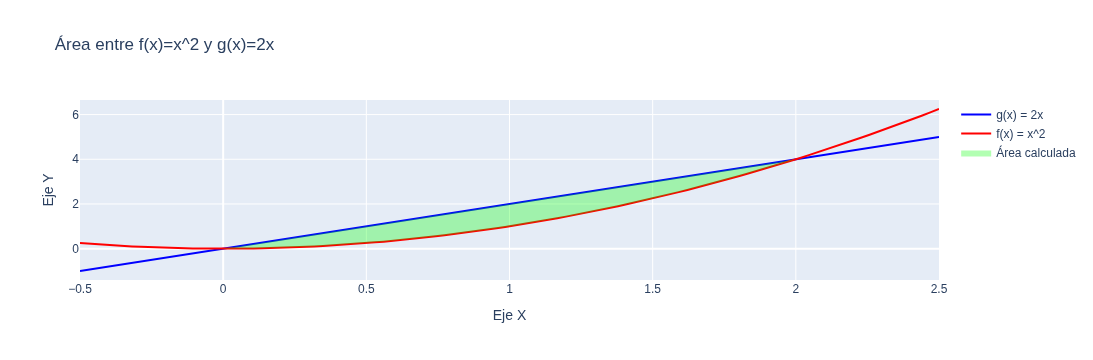

In [9]:
# 3. Calculamos la integral definida (Área bajo la curva) con SymPy
a = limites[0] # Límite inferior (0)
b = limites[1] # Límite superior (2)
area_exacta = sp.integrate(g - f, (x, a, b))
print(f"El área exacta entre las curvas es: {area_exacta} unidades cuadradas")

# 4. Traducimos las matemáticas de SymPy a números para poder graficar (usando NumPy)
f_num = sp.lambdify(x, f, 'numpy')
g_num = sp.lambdify(x, g, 'numpy')

# Creamos el eje X: 100 puntos desde un poco antes de 0 hasta un poco después de 2
x_vals = np.linspace(-0.5, 2.5, 100)
y_f = f_num(x_vals)
y_g = g_num(x_vals)

# 5. Empezamos a "dibujar" con Plotly
fig = go.Figure()

# Dibujamos la recta g(x) en azul
fig.add_trace(go.Scatter(x=x_vals, y=y_g, mode='lines', name='g(x) = 2x', line=dict(color='blue')))

# Dibujamos la parábola f(x) en rojo
fig.add_trace(go.Scatter(x=x_vals, y=y_f, mode='lines', name='f(x) = x^2', line=dict(color='red')))

# 6. Sombramos el área entre las dos curvas para que se vea profesional
x_fill = np.linspace(float(a), float(b), 50)
fig.add_trace(go.Scatter(
    x=np.concatenate([x_fill, x_fill[::-1]]), 
    y=np.concatenate([g_num(x_fill), f_num(x_fill)[::-1]]), 
    fill='toself', 
    fillcolor='rgba(0,255,0,0.3)', # Color verde semitransparente
    line=dict(color='rgba(255,255,255,0)'),
    name='Área calculada'
))

# Ponemos títulos y mostramos la gráfica
fig.update_layout(title='Área entre f(x)=x^2 y g(x)=2x', xaxis_title='Eje X', yaxis_title='Eje Y')
fig.show()

In [10]:
# 1. Definimos Pi de SymPy para cálculo exacto
pi = sp.pi

# Formula de Arandelas: pi * integral( g(x)^2 - f(x)^2 ) de a a b
integrando = g**2 - f**2
volumen_exacto = pi * sp.integrate(integrando, (x, a, b))

# Mostramos el resultado simbólico y aproximado
print(f"El volumen exacto usando el Método de Arandelas es:")
display(volumen_exacto) # Imprime con formato bonito de pi
print(f"Que es aproximadamente: {float(volumen_exacto.evalf()):.4f} unidades cúbicas")

El volumen exacto usando el Método de Arandelas es:


64⋅π
────
 15 

Que es aproximadamente: 13.4041 unidades cúbicas


In [17]:
# Importamos la herramienta para dividir la pantalla en 2
from plotly.subplots import make_subplots
import numpy as np
import plotly.graph_objects as go
import sympy as sp

# 1. Aseguramos las variables base en memoria
x = sp.Symbol('x')
a, b = 0, 2
f_num = sp.lambdify(x, x**2, 'numpy')
g_num = sp.lambdify(x, 2*x, 'numpy')

n_puntos = 100
n_angulos = 80
x_3d = np.linspace(float(a), float(b), n_puntos)

# 2. Sólido Principal (Izquierda)
theta_solido = np.linspace(0, 1.5 * np.pi, n_angulos)
X_sol, T_sol = np.meshgrid(x_3d, theta_solido)
R_ext_sol = g_num(X_sol)
R_int_sol = f_num(X_sol)

Y_ext = R_ext_sol * np.cos(T_sol)
Z_ext = R_ext_sol * np.sin(T_sol)
Y_int = R_int_sol * np.cos(T_sol)
Z_int = R_int_sol * np.sin(T_sol)

# 3. Arandela Aislada (Derecha)
x_corte = 1.5
theta_completo = np.linspace(0, 2 * np.pi, 100)
r_ext_c = g_num(x_corte)
r_int_c = f_num(x_corte)

Radios_arandela = np.linspace(r_int_c, r_ext_c, 15)
R_ara, T_ara = np.meshgrid(Radios_arandela, theta_completo)
X_ara = np.full_like(R_ara, x_corte)
Y_ara = R_ara * np.cos(T_ara)
Z_ara = R_ara * np.sin(T_ara)

# 4. CREACIÓN DE PANTALLA DIVIDIDA
fig = make_subplots(
    rows=1, cols=2,
    specs=[[{'type': 'surface'}, {'type': 'surface'}]],
    subplot_titles=('<b>Sólido Completo (Corte 270°)</b>', '<b>Arandela Extraída con Funciones</b>')
)

# ========================================================
# FUENTE GIGANTE Y UNIFORME PARA EL VIDEO
# ========================================================
fuente_video = dict(size=18, color="black", family="Arial Black")

# --- PANEL IZQUIERDO: SÓLIDO COMPLETO ---
fig.add_trace(go.Surface(x=X_sol, y=Y_ext, z=Z_ext, colorscale='Blues', showscale=False, opacity=0.5), row=1, col=1)
fig.add_trace(go.Surface(x=X_sol, y=Y_int, z=Z_int, colorscale='Reds', showscale=False, opacity=0.9), row=1, col=1)

# Dibujo de funciones y aros
fig.add_trace(go.Scatter3d(x=x_3d, y=g_num(x_3d), z=np.zeros_like(x_3d), mode='lines', line=dict(color='darkblue', width=6)), row=1, col=1)
fig.add_trace(go.Scatter3d(x=x_3d, y=f_num(x_3d), z=np.zeros_like(x_3d), mode='lines', line=dict(color='darkred', width=6)), row=1, col=1)

y_ext_c = r_ext_c * np.cos(theta_completo)
z_ext_c = r_ext_c * np.sin(theta_completo)
y_int_c = r_int_c * np.cos(theta_completo)
z_int_c = r_int_c * np.sin(theta_completo)

fig.add_trace(go.Scatter3d(x=np.full_like(theta_completo, x_corte), y=y_ext_c, z=z_ext_c, mode='lines', line=dict(color='green', width=5)), row=1, col=1)
fig.add_trace(go.Scatter3d(x=np.full_like(theta_completo, x_corte), y=y_int_c, z=z_int_c, mode='lines', line=dict(color='lightgreen', width=5)), row=1, col=1)

# Textos de Funciones Izquierda (Con fuente_video)
fig.add_trace(go.Scatter3d(
    x=[1.2, 1.2], y=[f_num(1.2)-2, f_num(1.2)], z=[0,0], 
    mode='lines+text', line=dict(color='black', dash='dash'), 
    text=['← f(x)=x²', ''], textposition='bottom center', textfont=fuente_video
), row=1, col=1)

fig.add_trace(go.Scatter3d(
    x=[0.8, 0.8], y=[g_num(0.8)+2, g_num(0.8)], z=[0,0], 
    mode='lines+text', line=dict(color='black', dash='dash'), 
    text=['← g(x)=2x', ''], textposition='top center', textfont=fuente_video
), row=1, col=1)

# Límites de Integración (Con fuente_video)
fig.add_trace(go.Scatter3d(
    x=[0], y=[0], z=[0], 
    mode='markers+text', marker=dict(size=8, color='black'), 
    text=['Límite a=0'], textposition='bottom left', textfont=fuente_video
), row=1, col=1)

fig.add_trace(go.Scatter3d(
    x=[2], y=[4], z=[0], 
    mode='markers+text', marker=dict(size=8, color='black'), 
    text=['Límite b=2'], textposition='middle right', textfont=fuente_video
), row=1, col=1)


# --- PANEL DERECHO: ARANDELA AISLADA ---
fig.add_trace(go.Surface(x=X_ara, y=Y_ara, z=Z_ara, colorscale='Greens', showscale=False, opacity=0.8), row=1, col=2)
fig.add_trace(go.Scatter3d(x=np.full_like(theta_completo, x_corte), y=y_ext_c, z=z_ext_c, mode='lines', line=dict(color='darkgreen', width=8)), row=1, col=2)
fig.add_trace(go.Scatter3d(x=np.full_like(theta_completo, x_corte), y=y_int_c, z=z_int_c, mode='lines', line=dict(color='darkred', width=8)), row=1, col=2)

x_segmento = np.linspace(1.3, 1.7, 20)
fig.add_trace(go.Scatter3d(x=x_segmento, y=g_num(x_segmento), z=np.zeros_like(x_segmento), mode='lines', line=dict(color='blue', width=10)), row=1, col=2)
fig.add_trace(go.Scatter3d(x=x_segmento, y=f_num(x_segmento), z=np.zeros_like(x_segmento), mode='lines', line=dict(color='red', width=10)), row=1, col=2)

# Textos de Arandela Derecha (Con fuente_video)
fig.add_trace(go.Scatter3d(
    x=[x_corte, x_corte], y=[0, 0], z=[r_ext_c + 1.5, r_ext_c], 
    mode='lines+text', line=dict(color='blue', width=4, dash='dot'), 
    text=['↓ R(x) = 2x (RADIO MAYOR)', ''], textposition='top center', textfont=fuente_video
), row=1, col=2)

fig.add_trace(go.Scatter3d(
    x=[x_corte, x_corte], y=[0, 0], z=[-1.5, r_int_c], 
    mode='lines+text', line=dict(color='red', width=4, dash='dot'), 
    text=['↑ r(x) = x² (RADIO MENOR)', ''], textposition='bottom center', textfont=fuente_video
), row=1, col=2)

# --- CONFIGURACIÓN FINAL ---
fig.update_layout(
    title_text='<b>Análisis Visual: Método de Arandelas</b>',
    title_font_size=24,
    showlegend=False,
    scene1=dict(xaxis_title='Eje X', yaxis_title='Eje Y', zaxis_title='Eje Z', camera=dict(eye=dict(x=1.5, y=-1.8, z=1.2))),
    scene2=dict(xaxis_title='Eje X (Grosor dx)', yaxis_title='Eje Y', zaxis_title='Eje Z', camera=dict(eye=dict(x=2.0, y=-0.5, z=0.5))),
    margin=dict(l=0, r=0, b=0, t=60)
)

fig.write_html("grafica_3d_panel_doble_final.html", auto_open=True)

Se está abriendo en una sesión de navegador existente.


[1:1:0100/000000.672835:ERROR:content/zygote/zygote_main_linux.cc:197] Failed sending zygote boot message: Broken pipe (32)
[19764:19764:0100/000000.674903:ERROR:content/zygote/zygote_linux.cc:662] write: Broken pipe (32)
